In [1]:
from IPython.display import display, Math, Latex

import pandas as pd
import numpy as np
import numpy_financial as npf
import yfinance as yf
import matplotlib.pyplot as plt
import random
from datetime import datetime

## CFM 101 — Group Assignment 2026
### Robo-Advising Challenge: Two Clients, Two Strategies

**Team Number:** 11 
**Team Member Names (three or four):** three

Enter the names of all participating members below (one name per line):
- Brian
- Vansh
- Jenny 

**Submission:** Friday, November 27, 2026, at 9:00 AM (Eastern), via Dropbox.  
**Submit this completed Jupyter notebook only.**

Your team must construct **both** portfolios from the supplied `Tickers.csv` file:

- **Client A — Growth:** $\$1,000,000$ CAD; seek the highest expected return.
- **Client B — Low Risk:** $\$750,000$ CAD; seek the lowest portfolio volatility.

Both clients require 10–20 eligible stocks, at most 15% in any stock and at most 40% in any sector. Read the full assignment handout for all eligibility, fee, currency, and competition rules. Do not hardcode the selected stocks. Check that tickers are valid. The supplied ticker universe will permit feasible portfolios.

**No generative AI may be used in preparing this assignment.**

## Data preparation and shared functions

Read `Tickers.csv`, check ticker eligibility, retrieve the data needed for your strategies, and create any functions you will reuse for both clients. Use closing prices from **November 27, 2026** for the purchase calculations. All portfolio values and weights must be calculated in CAD, with purchase fees paid from the client budget.

Some global variables

In [2]:
# our group number
group = 11

# dates for filtering / data cleaning
filter_start = "2025-10-01"
filter_end = "2026-10-01"

# dates for historical analysis
period_start = "2023-10-01"
period_end = "2026-10-01"

# dates for competition
buy_start = "2026-11-17" # CHANGE BEFORE SUBMITTING,
day_after = "2026-11-18" # CHANGE BEFORE SUBMITTING,

# set budgets
budget_A = 1000000
budget_B = 750000

# max any stock can contribute to the portfolio
sector_limit = 0.40

# max any one sector can contribute to a portfolio
stock_limit = 0.15

# Min and max number of stocks
min_stocks = 10
max_stocks = 20

Functions to create final portfolio dataframes, and save them as csv file, giving back the budget reconciliation and fees too:

In [5]:
# function fees takes a number of shares, and returns the fee in USD for that purchase
def fees(shares):
    return min(2.15, 0.001 * shares)

def make_base_table(portfolio, budget):
    tickers = list(portfolio.keys())

    data = yf.download(tickers, start = buy_start, end = day_after, threads=False)["Close"]

    usd_to_cad = yf.download("CAD=X", start = buy_start, end = day_after, threads=False)["Close"].iloc[0,0]

    table = {
        "Ticker": [], 
        "Price": [], 
        "Currency": [], 
        "Weight": [], 
        "Price CAD": [],
        "Estimated Fees": []
    }

    for tick in tickers:
        price = data.loc[buy_start, tick]
        currency = stock_info.loc[tick, "Currency"]

        if currency == "USD":
            price_cad = price * usd_to_cad
        else:
            price_cad = price

        estimated_shares = portfolio[tick] * budget / price_cad
        estimated_fees = fees(estimated_shares) * usd_to_cad
        
        table["Ticker"].append(tick)
        table["Price"].append(price)
        table["Currency"].append(currency)
        table["Weight"].append(portfolio[tick])
        table["Price CAD"].append(price_cad)
        table["Estimated Fees"].append(estimated_fees)
        
    table = pd.DataFrame(table)
    
    return table, table["Estimated Fees"].sum(), usd_to_cad

def final_table(portfolio, budget):

    # first create a base table missing some data, but calculating estimated fees
    # store values we need from that base table
    base_table, estimated_fees, usd_to_cad = make_base_table(portfolio, budget)

    tickers = list(portfolio.keys())
        
    table = base_table.copy()

    investable = budget - estimated_fees
    table["Shares"] = table["Weight"] * investable / table["Price CAD"]
    table["Value"] = table["Shares"] * table["Price CAD"]
    table["Weight"] = table["Value"] / table["Value"].sum()

    actual_fees = 0

    for i in range(len(tickers)):
        actual_fees += fees(table.loc[i, "Shares"]) * usd_to_cad

    # Drop unneeded columns, and reorder columns
    table = table.drop(columns=["Price CAD", "Estimated Fees"])
    table = table[["Ticker", "Price", "Currency", "Shares", "Value", "Weight"]]

    # Calculate total CAD spent for budget reconciliation
    total_cost = table["Value"].sum() + actual_fees
    
    # Reindex final table
    table.index = range(1, len(table.index) + 1)
    
    # Create dataframe for csv file output
    file_table = table[["Ticker", "Shares"]]

    # Create option based on the budget to store the right kind of filename
    if budget == budget_A:
        option = "A"
    elif budget == budget_B:
        option = "B"
    
    file_table.to_csv(f"Stocks_Group_{group}_{option}.csv", index=False)
    
    return table, actual_fees, total_cost

Function to check that a portfolio is valid (to be run at the very end of portfolio creation):
Your checks must verify: valid/eligible tickers, stock count, maximum individual weight, maximum sector weight, weights summing to 100%, and total purchases plus fees within budget.

In [6]:
def validate_portfolio(table, actual_fees, total_cost, budget):
    
    tickers = table["Ticker"]

    # 1.1 every ticker is valid

    eligible = True
    
    for tick in tickers:
        t = yf.Ticker(tick)

        # Check if there is data in here (i.e. not a delisted or invalid ticker)
        if t.history(period="5d").empty:
            print(tick, "doesn't exist")
            eligible = False
            break
    
        # 1.2 every ticker is eligible

        # if the ticker is not in stock info's index (filtered list of eligible stocks)
        if tick not in eligible_tickers:
            print(tick, "not eligible")
            eligible = False
            break

    if eligible:
        print("PASS: tickers valid and eligible")
    else:
        print("FAIL: some tickers invalid / ineligible")


    # 2 valid stock count

    count = len(table.index)

    if count >= min_stocks and count <= max_stocks:
        print("PASS: valid stock count")
    else:
        print("FAIL: invalid stock count")

    # 3 and 4, maximum individual weight and weights sum

    weights_ok = True
    weights_sum = 0

    for i in table.index:
        weight = table.loc[i, "Value"] / table["Value"].sum()
        weights_sum += weight

        if weight > stock_limit:
            weights_ok = False
            break

    if weights_ok and weights_sum == 1: # WILL THIS FAIL CAUSE OF ROUNDING???
        print("PASS: valid weights")
    else:
        print("FAIL: invalid weights")

    # 5 maximum sector weight

    sectors_ok = True
    sector_weights = {}

    # initialize sector weights
    for tick in table["Ticker"].tolist():
        sector_weights[stock_info.loc[tick, "Sector"]] = 0

    for i in table.index:
        sector = stock_info.loc[table.loc[i, "Ticker"], "Sector"]
        sector_weights[sector] += table.loc[i, "Value"] / table["Value"].sum()

    for sector in sector_weights:
        if sector_weights[sector] > sector_limit:
            sectors_ok = False
            break

    if sectors_ok:
        print("PASS: valid sector weights")
    else:
        print("FAIL: invalid sector weights")

    # 6 total purchase cost and fees within budget

    if total_cost <= budget:
        print("PASS: purchases within budget")
    else:
        print("FAIL: purchases not within budget")
    print(f"Actual Fees: ${actual_fees:.2f} CAD")
    print(f"Total Cost: ${total_cost:.2f} CAD")
    

Extracting stocks / Data Cleaning:

In [7]:
# EXTRACTING TICKERS. MAKE SURE TO CHANGE FILE NAME FOR ACTUAL SUBMISSION
ticker_file = "Tickers.csv"
raw_tickers = pd.read_csv(ticker_file, header=None, names=["Ticker"]) 
tickers = raw_tickers["Ticker"].drop_duplicates().tolist()  
# deletes the repeated tickers

# my updates here：
# using .get() to avoid keyerror when a field is missing
# move the volume and close to a seperate cells
# add sector info for the 40% sector weight restriction

stock_rows = []

for tick in tickers:
    t = yf.Ticker(tick)
    information = t.get_info()

    # Check if there is data in here (i.e. not a delisted or invalid ticker)
    if t.history(period='max').empty:
        print(tick, "doesn't exist")
        continue
    
    # Check if it's a CAD or USD stock traded in CA or US market
    if information.get("market") not in ["ca_market", "us_market"]:
        print(tick, "wrong market")
        continue

    # Check if it's a stock and not something like a bond or index fund
    if information.get("quoteType") != "EQUITY":
        print(tick, "not stock")
        continue

    # check currency
    if information.get("currency") not in ["CAD", "USD"]:
        print(tick, "currency wrong")
        continue

    # check sector info
    if not information.get("sector"):
        print(tick, "sector missing")
        continue

    # save stock info for later processing
    stock_rows.append({
            "Ticker": tick,
            "Currency": information.get("currency"),
            "Sector": information.get("sector")
        })

stock_info = pd.DataFrame(stock_rows).set_index("Ticker") 
# set ticker as index
listed_tickers = stock_info.index.tolist()
# save the list for filter
display(stock_info.head())

$AGN: possibly delisted; no timezone found


AGN doesn't exist


$BK: possibly delisted; no price data found  (1d 1927-12-16 -> 2026-11-21)


BK doesn't exist


$CELG: possibly delisted; no timezone found


CELG doesn't exist


$MON: possibly delisted; no timezone found


MON doesn't exist


$RTN: possibly delisted; no timezone found


RTN doesn't exist


,Currency,Sector
Ticker,,
AAPL,USD,Technology
ABBV,USD,Healthcare
ABT,USD,Healthcare
ACN,USD,Technology
AIG,USD,Financial Services


In [8]:
# download historical exchange rate data
history = yf.download(
    listed_tickers + ["CAD=X"],
    start=period_start,
    end=period_end,
    threads=False,
)

# download close, volume and foreign exchange info
close_prices = history["Close"][listed_tickers]
# get closing price info
volume_data = history["Volume"][listed_tickers]
# get volume info
cad_per_usd = history["Close"]["CAD=X"]
# get USD to CAD exchange info

[*********************100%***********************]  36 of 36 completed


In [9]:
# create a seperate volume data for filter
volume_data = volume_data.loc[(volume_data.index >= filter_start) & (volume_data.index < filter_end)]
print(f"volume screening period: {volume_data.index.min()}, {volume_data.index.max()}")

# updates:
# average daily trading volume = total volume traded over a period (volume) / # of trading dasy in the period
# since months with fewer than 18 valid trading days may affect the average daily trading volume
# 1. filter out months with fewer than 18 valid trading days before calculating liquidity
# 2. use only eligible months to calculate liquidity and determine eligible_tickers

eligible_tickers = []
average_volume = {} 

for ticker in listed_tickers:
    volume = volume_data[ticker].dropna()  
    # delete missed value
    volume_days = []

    for month, monthly_volume in volume.groupby(volume.index.to_period("M")): 
        if len(monthly_volume) >= 18:  
            volume_days.extend(monthly_volume)  

    average_volume[ticker] = pd.Series(volume_days).mean()  
    # transfer list to series to calculate average trading volume
    if average_volume[ticker] >= 5_000:
        eligible_tickers.append(ticker)

stock_info["Average Daily Volume"] = pd.Series(average_volume)  
print(f"{len(eligible_tickers)} eligible stocks.")

display(stock_info["Average Daily Volume"].head())

volume screening period: 2025-10-01 00:00:00, 2026-09-30 00:00:00
35 eligible stocks.


Ticker
AAPL    4.828203e+07
ABBV    6.281745e+06
ABT     1.008423e+07
ACN     6.116120e+06
AIG     4.324195e+06
Name: Average Daily Volume, dtype: float64

In [10]:
# updates:
# make sure all stocks are using the same currency

# convert prices to CAD
cad_prices = close_prices[eligible_tickers].copy()
for ticker in eligible_tickers:
    if stock_info.loc[ticker, "Currency"] == "USD":
        # if currency is USD, then change to CAD
        cad_prices[ticker] = cad_prices[ticker] * cad_per_usd
        # match closing price and exchange rate by date

cad_prices = cad_prices.dropna()  
# delete dates which missing info

In [11]:
# After all filtering, this is the table that contains all the complete data for the full consideration period, and valid stocks
# No CBIL.TO in this

display(cad_prices.head())

Ticker,AAPL,ABBV,ABT,ACN,AIG,AMZN,AXP,BA,BAC,BB.TO,...,PYPL,QCOM,SHOP.TO,T.TO,TD.TO,TXN,UNH,UNP,UPS,USB
Date,,,,,,,,,,,,,,,,,,,,,
2023-10-02,232.519125,180.319242,121.325726,393.013010,76.241141,175.725132,195.350723,254.954813,33.728007,6.02,...,78.610931,141.522601,73.839996,17.100687,70.040100,198.282192,655.916213,257.465521,174.719966,38.394420
2023-10-03,232.456387,180.677267,122.319412,393.376099,75.013721,170.570816,190.994113,258.372658,32.977463,5.98,...,77.500919,141.424391,70.440002,17.204716,69.378128,196.408622,654.323936,260.871020,174.530872,37.721734
2023-10-04,234.716928,181.429996,122.433567,398.388477,76.116885,174.105576,193.537686,255.990027,33.094827,5.86,...,79.408646,141.326160,72.230003,17.756868,69.195198,197.781073,657.373751,259.559025,174.915318,37.691547
2023-10-05,237.011686,181.598940,123.452862,399.757000,77.327386,173.121948,195.441646,256.040701,33.333052,5.20,...,78.130367,141.623504,71.510002,18.100964,69.997543,194.697602,666.297724,258.126533,174.975326,38.550104
2023-10-06,239.833951,182.060462,123.977228,401.894122,78.033778,175.378129,197.848932,256.817403,33.252432,5.15,...,78.304584,142.615890,73.269997,18.044947,70.359047,196.517909,675.474489,259.738334,175.497638,38.430051


## Client B — Low Risk

Construct a portfolio intended to achieve the **lowest risk**, defined as the standard deviation of daily portfolio returns in CAD. Create `Portfolio_Final_B` using the same DataFrame column names, order, and index convention as for Client A.

Step 1. Create dataframe to store daily CAD close price of S&P 500 market index.
- explain why chose S&P 500 (represents US stocks, also largely Canadians too, most diversified, its equal weight)
- converted to CAD to allow CAD calculations of beta

In [12]:
market_history = yf.download("^GSPC", start=period_start, end=period_end, threads=False)["Close"]

market_cad = (market_history["^GSPC"] * cad_per_usd).to_frame("Market")

# drop days where mismatch in market exchange and S&P500 availability
market_cad = market_cad.dropna()

# Merge SP500 and valid tickers dataframes, dropping any dates with mismatch in markets
aligned_prices = pd.concat([cad_prices[eligible_tickers], market_cad], axis=1, join="inner").dropna()
# Calculate returns, dropping days (list first day) with no valid calculation
aligned_returns = aligned_prices.pct_change().iloc[1:].dropna()

# Aligned_prices is used for closing price data for all subsequent calculations
display(aligned_prices.head())
# Aligned_returns is used for daily return data for all subsequent calculations
display(aligned_returns.head())

[*********************100%***********************]  1 of 1 completed


,AAPL,ABBV,ABT,ACN,AIG,AMZN,AXP,BA,BAC,BB.TO,...,QCOM,SHOP.TO,T.TO,TD.TO,TXN,UNH,UNP,UPS,USB,Market
Date,,,,,,,,,,,,,,,,,,,,,
2023-10-02,232.519125,180.319242,121.325726,393.013010,76.241141,175.725132,195.350723,254.954813,33.728007,6.02,...,141.522601,73.839996,17.100687,70.040100,198.282192,655.916213,257.465521,174.719966,38.394420,5820.932201
2023-10-03,232.456387,180.677267,122.319412,393.376099,75.013721,170.570816,190.994113,258.372658,32.977463,5.98,...,141.424391,70.440002,17.204716,69.378128,196.408622,654.323936,260.871020,174.530872,37.721734,5784.322991
2023-10-04,234.716928,181.429996,122.433567,398.388477,76.116885,174.105576,193.537686,255.990027,33.094827,5.86,...,141.326160,72.230003,17.756868,69.195198,197.781073,657.373751,259.559025,174.915318,37.691547,5845.217719
2023-10-05,237.011686,181.598940,123.452862,399.757000,77.327386,173.121948,195.441646,256.040701,33.333052,5.20,...,141.623504,71.510002,18.100964,69.997543,194.697602,666.297724,258.126533,174.975326,38.550104,5852.541619
2023-10-06,239.833951,182.060462,123.977228,401.894122,78.033778,175.378129,197.848932,256.817403,33.252432,5.15,...,142.615890,73.269997,18.044947,70.359047,196.517909,675.474489,259.738334,175.497638,38.430051,5905.100605


,AAPL,ABBV,ABT,ACN,AIG,AMZN,AXP,BA,BAC,BB.TO,...,QCOM,SHOP.TO,T.TO,TD.TO,TXN,UNH,UNP,UPS,USB,Market
Date,,,,,,,,,,,,,,,,,,,,,
2023-10-03,-0.000270,0.001986,0.008190,0.000924,-0.016099,-0.029332,-0.022301,0.013406,-0.022253,-0.006645,...,-0.000694,-0.046045,0.006083,-0.009451,-0.009449,-0.002428,0.013227,-0.001082,-0.017520,-0.006289
2023-10-04,0.009725,0.004166,0.000933,0.012742,0.014706,0.020723,0.013318,-0.009222,0.003559,-0.020067,...,-0.000695,0.025412,0.032093,-0.002637,0.006988,0.004661,-0.005029,0.002203,-0.000800,0.010528
2023-10-05,0.009777,0.000931,0.008325,0.003435,0.015903,-0.005650,0.009838,0.000198,0.007198,-0.112628,...,0.002104,-0.009968,0.019378,0.011595,-0.015590,0.013575,-0.005519,0.000343,0.022779,0.001253
2023-10-06,0.011908,0.002541,0.004248,0.005346,0.009135,0.013032,0.012317,0.003034,-0.002419,-0.009615,...,0.007007,0.024612,-0.003095,0.005165,0.009349,0.013773,0.006244,0.002985,-0.003114,0.008981
2023-10-10,-0.004110,-0.004790,-0.002180,-0.008722,-0.004251,0.002635,0.001548,0.023386,0.026593,-0.048544,...,0.003644,0.020882,0.005322,0.009022,-0.004969,-0.010211,0.009903,-0.000914,0.013569,0.002304


Step 2.
- comput stats to be used for each stock

In [13]:
# updates
# approach to calculate mean, std, and beta, which gives equal weight to all data
# it is used for the low-risk portfolio selection only so far

# Get rid of market from new returns dataframe
daily_returns = aligned_returns[eligible_tickers]

# calculate the mean daily returns of each stock
mean_returns = daily_returns.mean()  

# calculate the standard deviation of daily returns of stocks
daily_std = daily_returns.std(ddof=1)  

# calculate beta for each stock:
market_var = aligned_returns["Market"].var()

# Calc and store beta for each valid stock
betas = {}
for tick in eligible_tickers:
    temp = aligned_returns[[tick, "Market"]]
    betas[tick] = (temp.cov() / market_var).iat[0, 1] 

# turn dict into a series (column to be added)
betas = pd.Series(betas)

stock_stats = stock_info.loc[eligible_tickers].copy()
stock_stats["Mean Return"] = mean_returns
stock_stats["Std"] = daily_std
stock_stats["Beta"] = betas

# These are the dataframes with the statistics we need
display(daily_returns.iloc[:5, :5])
display(stock_stats.head())


# Calculate risk score for each stock (equal weight average of std and beta)


,AAPL,ABBV,ABT,ACN,AIG
Date,,,,,
2023-10-03,-0.000270,0.001986,0.008190,0.000924,-0.016099
2023-10-04,0.009725,0.004166,0.000933,0.012742,0.014706
2023-10-05,0.009777,0.000931,0.008325,0.003435,0.015903
2023-10-06,0.011908,0.002541,0.004248,0.005346,0.009135
2023-10-10,-0.004110,-0.004790,-0.002180,-0.008722,-0.004251


,Currency,Sector,Average Daily Volume,Mean Return,Std,Beta
Ticker,,,,,,
AAPL,USD,Technology,4.828203e+07,0.001117,0.017513,1.080500
ABBV,USD,Healthcare,6.281745e+06,0.001108,0.016273,0.356590
ABT,USD,Healthcare,1.008423e+07,0.000300,0.014879,0.254820
ACN,USD,Technology,6.116120e+06,-0.000335,0.021639,0.688471
AIG,USD,Financial Services,4.324195e+06,0.000552,0.014738,0.553412


Step 3. Rank all stocks using their daily std and beta.
Our reasoning:
- continuity in ranking doesn't lose info or make stocks with different risk assessment equal according to algo
- std measures how risky it is, beta measures how much it moves with overall market
- can't reduce market risk with diversification but can minimize it by reducing beta of stocks chosen
- use to construct portfolio using safest stocks first

- explain that we use beta parameters similar to the trading period (daily, etc.)

- we do not use arbitrary scores and add them to combine, instead we standardize them to a z score (assumed normal distribution), then give equal weight to each
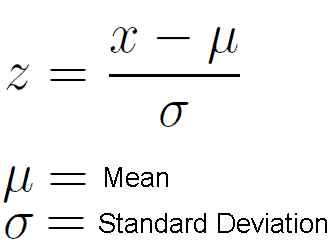

In [14]:
# calculate std z score and beta z score and add to the table above

std_weight = 0.5 # Can back test to see what's the ideal weighting if we have time
beta_weight = 0.5

std_z = (stock_stats["Std"] - stock_stats["Std"].mean()) / stock_stats["Std"].std()
beta_z = (stock_stats["Beta"] - stock_stats["Beta"].mean()) / stock_stats["Beta"].std()

# Combine z scores into a risk score in the dataframe
stock_stats["Risk Score"] = std_weight * std_z + beta_weight * beta_z

# Sort the dataframe, lower risk score is safer
stock_stats = stock_stats.sort_values("Risk Score")

# convert risk score sorted stocks into a list
ranked = stock_stats.index.tolist()

display(stock_stats.head())

,Currency,Sector,Average Daily Volume,Mean Return,Std,Beta,Risk Score
Ticker,,,,,,,
KO,USD,Consumer Defensive,1.665754e+07,0.000836,0.010964,0.104581,-1.226049
T.TO,CAD,Communication Services,7.888837e+06,-0.000411,0.012284,0.003825,-1.218949
CL,USD,Consumer Defensive,5.909059e+06,0.000493,0.012792,0.113328,-1.070919
MO,USD,Consumer Defensive,9.059322e+06,0.001119,0.014098,0.032148,-1.045777
PEP,USD,Consumer Defensive,7.808363e+06,-0.000097,0.013260,0.162332,-0.985400


Step 4. Greedy picker:
greedy picker algorithm picks the next stock in the table that:
- reduces std by the most amount (given equal weight between current portfolio and the new stock)
- track a tally of number of stocks in each industry
- track a tally of all stocks in the portfolio
- If the stocks in total is still not enough, allow the reduction of std to be positive, i.e. gain in std but by littlest amount to meet portfolio requirements
- Stop when minimum number of stocks is met and also adding more increases std, so not necessarily all 20 stocks but will be near it, and will avoid taking high volatlity stocks with the highest risk scores


In [15]:
# create combined_std, a function which calculates the std of an equal weighted portfolio given the list of its tickers, tickers
def combined_std(tickers):

    # every stock gets equal weight
    weights = 1 / len(tickers)

    returns = 0
    
    for tick in tickers:
        returns = returns + weights * daily_returns[tick]
        
    # return standard deviation of daily portfolio returns
    return returns.std(ddof=1)

In [16]:
# dict to store running tally of number of stocks from each sector
sector_tally = {}

# max number of stocks per sector = 40% of minimum 10 stocks = 4 stocks per sector, also adds industry diversification to reduce business risk
max_per_sector = int(sector_limit * min_stocks)
# IM NOT SURE EXACTLY HOW THIS CAN BE MADE DYNAMIC? WE DONT HAVE THE TOTAL NUMBER OF STOCKS OR EVEN THE WEIGHTINGS SO NOT MUCH WE CAN DO?

# list to store selected stocks for portfolio
selected = []

# initialize tally for each sector so far
for tick in ranked:
    sector_tally[stock_stats.loc[tick, "Sector"]] = 0

# start with the safest stock in selected
selected.append(ranked[0])

# add 1 to its sector tally
sector_tally[stock_stats.loc[ranked[0], "Sector"]] = 1

# total number of stocks in portfolio
total_count = 1

# std of current portfolio to compare to
current_std = combined_std(selected)

# allow safe stocks to be added if they increase std very slightly, since they still reduce risk to shocks, by holding less in any 1 stock
std_tolerance = 0 * current_std
# CURRENTLY SET TO 0 CHANGE LATER? AFTER TEAM CALL

while total_count < max_stocks:
    # starting std of portfolio in current iteration (whatever stocks are in selected + the best stock found so far down the ranked list)
    best_tick = None
    best_std = None

    # loop through safe ranked stocks top down
    for tick in ranked:
        # skip any stocks already chosen for portfolio
        if tick in selected:
            continue

        # find the current stock's sector
        sector = stock_stats.loc[tick, "Sector"]
        # temporarily add 1 to that sector's tally for a check
        temp_tally = sector_tally[sector] + 1

        # if adding another stock from that sector goes over the limit, skip that stock
        if temp_tally > max_per_sector:
            continue
            
        # calculate std if this stock were to be added to portfolio
        new_std = combined_std(selected + [tick])

        # skip the stock if the new std is worse
        if best_std is not None and new_std >= best_std:
            continue

        # if the stock passed all the tests
        best_tick = tick
        best_std = new_std

    # no stock fits requirements to be added to portfolio, so go with current portfolio
    if best_tick is None:
         break

    # how much is this new portfolio's std compared to old one's
    change = best_std - current_std

    # if adding the stock worsens std and we have already met minimum stock requirement, don't add it
    #if change >= std_tolerance and total_count >= min_stocks:
    #    break
    # REMOVE THIS??? We can take 20 for now and do the weight optimation later?

    # otherwise: adding the stock lowers std, or we still need more stocks to reach the minimum
    selected.append(best_tick)
    sector_tally[stock_stats.loc[best_tick, "Sector"]] += 1
    total_count += 1
    current_std = best_std

print("Selected:", selected)
print("Total stocks:", total_count)
print("Stocks per sector:", sector_tally)
print("Equal-weight portfolio daily std:", current_std)

# NOTE THIS IS NOT THE SAME AS JUST TAKING TOP 20 STOCKS FROM RANKED LIST, IT INCLUDES SOME THAT ARE THERE CUZ OF PAIRED COVARIANCE BEING OPPOSITE LIKE AMAZON

Selected: ['KO', 'RY.TO', 'TD.TO', 'T.TO', 'LMT', 'MO', 'AMZN', 'CL', 'ABT', 'CAT', 'PEP', 'UNH', 'AIG', 'PFE', 'AAPL', 'ABBV', 'UNP', 'BAC', 'ACN', 'BB.TO']
Total stocks: 20
Stocks per sector: {'Consumer Defensive': 4, 'Communication Services': 1, 'Financial Services': 4, 'Healthcare': 4, 'Industrials': 3, 'Technology': 3, 'Consumer Cyclical': 1}
Equal-weight portfolio daily std: 0.007476334139584248


Step 5. Weight Optimization:
- using correlation matrix


In [17]:
half_life = 100

In [18]:
def weighted_corr(t1, t2):
    d1 = daily_returns[t1]
    d2 = daily_returns[t2]
    return d1.ewm(halflife=half_life).corr(d2).dropna().iloc[-1]

In [19]:
corr_mat = pd.DataFrame()

for t1 in selected:
    for t2 in selected:
        corr_mat.loc[t1, t2] = weighted_corr(t1, t2)

plain_corr = daily_returns[selected].corr()

cov_mat = pd.DataFrame()

for t1 in selected:
    for t2 in selected:
        cov_mat.loc[t1, t2] = plain_corr.loc[t1, t2] * daily_std[t1] * daily_std[t2]

In [ ]:
display(corr_mat)
display(cov_mat)

## DUMMY PORTFOLIO TESTING VALIDATION FUNCTIONS AND FINAL CSV / DATAFRAME FUNCTION

In [22]:
dummy = {"AAPL": 0.5, "KO": 0.5}

table, fees_B, costs = final_table(dummy, budget_B)

display(table)
print(fees_B)
print(costs)

validate_portfolio(table, fees_B, costs, budget_B)

[*********************100%***********************]  2 of 2 completed
[*********************100%***********************]  1 of 1 completed


,Ticker,Price,Currency,Shares,Value,Weight
1,AAPL,351.910004,USD,745.336408,374997.930266,0.5
2,KO,98.790001,USD,2655.039331,374997.930266,0.5


4.139462511031606
749999.9999941186
PASS: tickers valid and eligible
FAIL: invalid stock count
FAIL: invalid weights
FAIL: invalid sector weights
PASS: purchases within budget
Actual Fees: $4.14 CAD
Total Cost: $750000.00 CAD


### Client B — Financial justification

**Why does this portfolio make financial sense?** Explain how and why you select and weight stocks.

**What evidence supports your strategy?** Discuss relevant statistics and the equal-weight comparison below.

**What could go wrong?** Identify at least one important limitation or situation in which this strategy may perform poorly.

## HIGH RETURNS PORTFOLIO:

Sharpe calculation

In [ ]:
# Add complete CBIL.TO data to cad_prices to create full_data

full_data = cad_prices.copy()

full_data["CBIL.TO"] = yf.download("CBIL.TO", period_start, period_end, auto_adjust=True)["Close"]

display(full_data.head())

In [ ]:
def get_stats(tick, half_life):
    s = full_data[tick].dropna()
    delta = np.log(1 + s.pct_change()).ewm(halflife = half_life)
    standard_deviation = delta.std().iloc[-1]
    average = delta.mean().iloc[-1]

    return average, standard_deviation

In [ ]:
Rf = get_stats("CBIL.TO", half_life)[0]
print("Risk free return:", Rf)

sharpe = {}

for tick in close_prices:
    stats = get_stats(tick, half_life)
    sharpe[tick] = (stats[0] - Rf)/stats[1]

sharpe = dict(sorted(sharpe.items(), key = lambda item:item[1]))
print(sharpe)